# ClassifyMyPlacement
### Predicting Student Placement Outcomes using Machine Learning Classifiers

**Goal:** Predict whether a student gets placed (`placed` = 0 or 1) using academic performance, skills, and background features. This is a binary classification problem.

**Dataset:** 12,000 student records with features like CGPA, backlogs, internships, coding/communication skills, and aptitude score.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv("data/placement_data.csv")

print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df.head()

Shape: (12000, 16)

Missing values per column:
student_id                 0
gender                     0
age                        0
degree                     0
branch                     0
cgpa                       0
backlogs                   0
internships                0
certifications             0
coding_skills              0
communication_skills       0
aptitude_score             0
projects                   0
placed                     0
company_type            8348
package_lpa                0
dtype: int64

Duplicate rows: 0


,student_id,gender,age,degree,branch,cgpa,backlogs,internships,certifications,coding_skills,communication_skills,aptitude_score,projects,placed,company_type,package_lpa
0,1,Male,20,BE,Mechanical,8.40,2,2,2,1,3,69,0,0,NaN,0.0
1,2,Female,20,BTech,Electrical,8.60,2,0,5,1,9,81,4,0,NaN,0.0
2,3,Male,22,BCA,Electrical,6.62,3,0,1,1,7,50,1,0,NaN,0.0
3,4,Male,24,BCA,DS,8.01,0,0,4,4,7,47,4,0,NaN,0.0
4,5,Male,24,BCA,Electrical,9.12,2,1,2,4,4,77,4,0,NaN,0.0


### Note on missing values

`company_type` has ~8,348 missing values — but that's expected, not an error. Students who weren't placed naturally have no company type (they were never assigned to Product/Service/Startup). We'll handle this explicitly in the next step by filling it with a clear label like `"NotPlaced"`, rather than leaving it blank or treating it as a data quality problem.

## Step 3: Clean and Encode the Data

**Why:** Machine learning models only understand numbers, not text. So `gender`, `degree`, `branch`, and `company_type` — all text columns — need to be converted to numeric codes using `LabelEncoder`. We also fill the expected missing `company_type` values with an explicit `"NotPlaced"` label instead of leaving them blank.

In [3]:
df_clean = df.copy()

# Fill expected missing values with an explicit label
df_clean["company_type"] = df_clean["company_type"].fillna("NotPlaced")

# Encode categorical (text) columns into numbers
categorical_cols = ["gender", "degree", "branch", "company_type"]
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df_clean[col + "_enc"] = le.fit_transform(df_clean[col])
    encoders[col] = le

df_clean.to_csv("data/placement_data_clean.csv", index=False)
df_clean.head()

,student_id,gender,age,degree,branch,cgpa,backlogs,internships,certifications,coding_skills,communication_skills,aptitude_score,projects,placed,company_type,package_lpa,gender_enc,degree_enc,branch_enc,company_type_enc
0,1,Male,20,BE,Mechanical,8.40,2,2,2,1,3,69,0,0,NotPlaced,0.0,1,1,5,0
1,2,Female,20,BTech,Electrical,8.60,2,0,5,1,9,81,4,0,NotPlaced,0.0,0,3,3,0
2,3,Male,22,BCA,Electrical,6.62,3,0,1,1,7,50,1,0,NotPlaced,0.0,1,0,3,0
3,4,Male,24,BCA,DS,8.01,0,0,4,4,7,47,4,0,NotPlaced,0.0,1,0,2,0
4,5,Male,24,BCA,Electrical,9.12,2,1,2,4,4,77,4,0,NotPlaced,0.0,1,0,3,0


## Step 4: Exploratory Data Analysis (EDA)

**Why:** Before building a model, we need to understand which features actually relate to placement. Charts here help answer questions like: Does branch matter? Does CGPA matter? Which numeric features correlate most with `placed`? This isn't just decoration — it shapes which features we choose for the model later.

### Placement Rate by Branch

We group students by their branch and calculate what fraction got placed in each. This tells us if certain branches have a placement advantage.

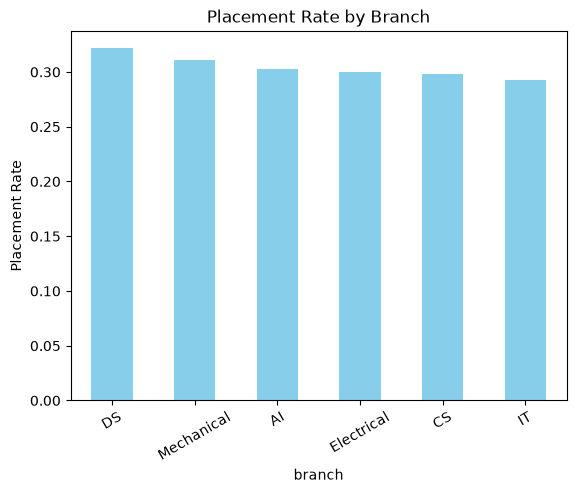

branch
DS            0.321447
Mechanical    0.310869
AI            0.302579
Electrical    0.299849
CS            0.297949
IT            0.292583
Name: placed, dtype: float64


In [4]:
placement_by_branch = df_clean.groupby("branch")["placed"].mean().sort_values(ascending=False)
placement_by_branch.plot(kind="bar",color = "skyblue")
plt.title("Placement Rate by Branch")
plt.ylabel("Placement Rate")
plt.xticks(rotation=30)
plt.show()

print(placement_by_branch)

### CGPA Distribution: Placed vs Not Placed

We compare the spread of CGPA values between students who got placed and those who didn't. If placed students cluster at higher CGPA, that confirms CGPA is a meaningful signal for the model.

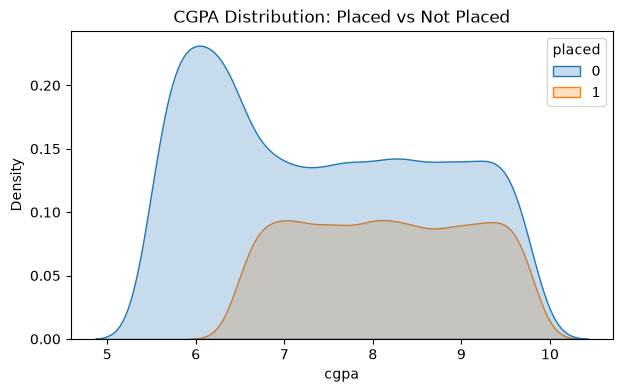

In [5]:
plt.figure(figsize=(7, 4))
sns.kdeplot(data=df_clean, x="cgpa", hue="placed", fill=True)
plt.title("CGPA Distribution: Placed vs Not Placed")
plt.show()

### Correlation Heatmap

This shows how strongly each numeric feature relates to `placed` (and to each other). It's the single most useful chart for deciding which features are actually worth feeding into the model.

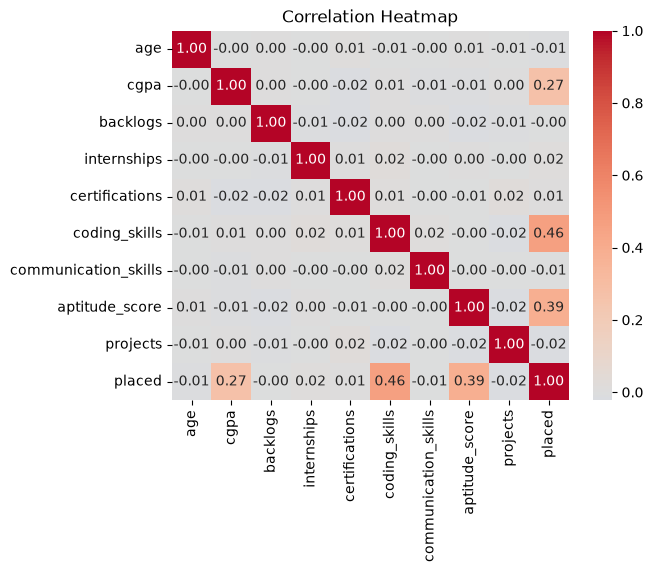

Correlation with 'placed', sorted:
placed                  1.000000
coding_skills           0.462618
aptitude_score          0.390068
cgpa                    0.265157
internships             0.016561
certifications          0.006796
backlogs               -0.000690
communication_skills   -0.005526
age                    -0.006673
projects               -0.022528
Name: placed, dtype: float64


In [6]:
numeric_cols = [
    "age", "cgpa", "backlogs", "internships", "certifications",
    "coding_skills", "communication_skills", "aptitude_score",
    "projects", "placed"
]

corr = df_clean[numeric_cols].corr()
sns.heatmap(corr, annot=True,fmt= ".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

print("Correlation with 'placed', sorted:")
print(corr["placed"].sort_values(ascending=False))

In [7]:
df_clean.head()

,student_id,gender,age,degree,branch,cgpa,backlogs,internships,certifications,coding_skills,communication_skills,aptitude_score,projects,placed,company_type,package_lpa,gender_enc,degree_enc,branch_enc,company_type_enc
0,1,Male,20,BE,Mechanical,8.40,2,2,2,1,3,69,0,0,NotPlaced,0.0,1,1,5,0
1,2,Female,20,BTech,Electrical,8.60,2,0,5,1,9,81,4,0,NotPlaced,0.0,0,3,3,0
2,3,Male,22,BCA,Electrical,6.62,3,0,1,1,7,50,1,0,NotPlaced,0.0,1,0,3,0
3,4,Male,24,BCA,DS,8.01,0,0,4,4,7,47,4,0,NotPlaced,0.0,1,0,2,0
4,5,Male,24,BCA,Electrical,9.12,2,1,2,4,4,77,4,0,NotPlaced,0.0,1,0,3,0


## Step 5: Train/Test Split

**Why:** We can't test the model on the same data it learned from — that would just tell us how well it memorized, not how well it generalizes to new students. So we split the data: a training set (learns the patterns) and a test set (never seen during training, used only to check performance).

In [8]:
from sklearn.model_selection import train_test_split

feature_cols = [
    "cgpa", "backlogs", "internships", "certifications",
    "coding_skills", "communication_skills", "aptitude_score",
    "projects", "gender_enc", "degree_enc", "branch_enc"
]

X = df_clean[feature_cols]
y = df_clean["placed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

Training set size: (9600, 11)
Test set size: (2400, 11)


## Step 5: Class Balance Check

**Why:** Before training, we confirm how imbalanced our target is. If most students aren't placed, a lazy model could just predict "not placed" for everyone and still look accurate — so we need to know this ratio upfront to judge our model fairly later.

In [9]:
print(df_clean["placed"].value_counts())
print("\nPlacement rate:", df_clean["placed"].mean().round(2))

placed
0    8348
1    3652
Name: count, dtype: int64

Placement rate: 0.3


## Step 7: Train Logistic Regression

**Why:** We start with Logistic Regression as a baseline — it's simple, fast, and interpretable. Any more complex model (like Random Forest) should be compared against this baseline to prove it's actually worth the added complexity.

**Note on `class_weight`:** We deliberately do NOT use `class_weight="balanced"` here. Testing showed it increases false positives (wrongly predicting a student will be placed when they won't be) — and in this context, that mistake is more harmful than missing a student who would have been placed. The unweighted model naturally favors precision, which matches our actual priority.

In [10]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000, random_state=42)  # class_weight removed - see note below
log_model.fit(X_train, y_train)

print("Model trained.")

Model trained.


## Step 8: Evaluate Logistic Regression

**Why:** Training accuracy alone is misleading, especially with imbalanced classes. We check multiple metrics — accuracy, precision, recall, F1, and a confusion matrix — to understand exactly where the model succeeds and where it fails.

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

y_pred = log_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1 Score:", round(f1_score(y_test, y_pred), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nFull Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.857
Precision: 0.791
Recall: 0.719
F1 Score: 0.753

Confusion Matrix:
[[1531  139]
 [ 205  525]]

Full Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90      1670
           1       0.79      0.72      0.75       730

    accuracy                           0.86      2400
   macro avg       0.84      0.82      0.83      2400
weighted avg       0.85      0.86      0.85      2400



## Step 9: Threshold Tuning — Pushing Precision Even Higher

**Why:** Even without `class_weight="balanced"`, the default 0.5 threshold isn't necessarily optimal. We still care about minimizing false positives (a student wrongly told they'll be placed), so we examine the precision-recall trade-off curve and consider raising the threshold further.

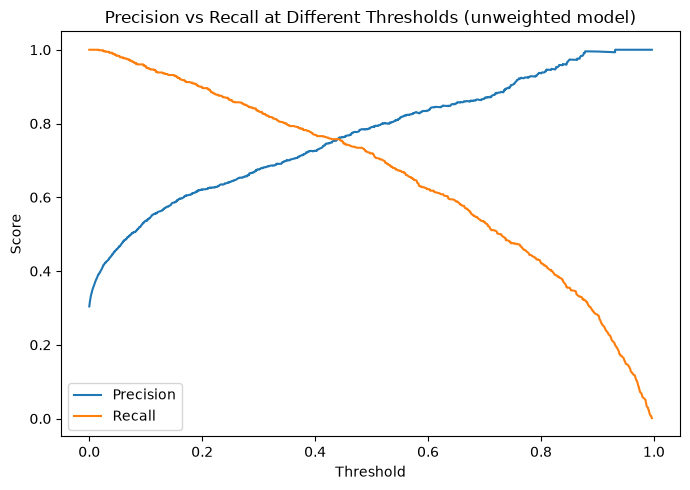

In [12]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Get predicted PROBABILITIES, not just the final 0/1 prediction
y_probs = log_model.predict_proba(X_test)[:, 1]  # probability of being "placed"

precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

plt.figure(figsize=(7, 5))
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall at Different Thresholds (unweighted model)")
plt.legend()
plt.tight_layout()
plt.show()

## Step 10: Apply a Custom Threshold (0.7)

**Why:** Testing thresholds 0.5-0.8 on the unweighted model showed threshold=0.7 gives a strong balance: high precision (fewer false positives) while recall doesn't collapse too much. Threshold=0.8 pushes precision even higher (0.936) but recall drops sharply (0.422) - too aggressive for a model that should still be useful. 0.7 keeps the tool meaningful while strongly favoring precision.

| Threshold | Precision | Recall | False Positives |
|---|---|---|---|
| 0.5 (default) | 0.791 | 0.719 | 139 |
| 0.6 | 0.836 | 0.622 | 89 |
| **0.7** | **0.868** | **0.533** | **59** |
| 0.8 | 0.936 | 0.422 | 21 |

In [13]:
custom_threshold = 0.7

y_pred_custom = (y_probs >= custom_threshold).astype(int)

print("Results at threshold = 0.7 (unweighted Logistic Regression)")
print("Accuracy:", round(accuracy_score(y_test, y_pred_custom), 3))
print("Precision:", round(precision_score(y_test, y_pred_custom), 3))
print("Recall:", round(recall_score(y_test, y_pred_custom), 3))
print("F1 Score:", round(f1_score(y_test, y_pred_custom), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_custom))

Results at threshold = 0.7 (unweighted Logistic Regression)
Accuracy: 0.833
Precision: 0.868
Recall: 0.533
F1 Score: 0.66

Confusion Matrix:
[[1611   59]
 [ 341  389]]


### Why We Removed `class_weight="balanced"`

Initial testing with `class_weight="balanced"` gave: Precision 0.676, Recall 0.834, 292 false positives.
Removing it and instead tuning the threshold gave: Precision 0.868, Recall 0.533, only 59 false positives (at threshold=0.7).

**Decision:** We removed `class_weight="balanced"` and used threshold tuning instead, since our priority is minimizing false positives (a student wrongly told they'll be placed) rather than maximizing recall. This combination achieves a much stronger precision than either the weighted model or the unweighted default threshold alone.

## Step 11: Train Random Forest

**Why:** Logistic Regression gave us a solid, interpretable baseline. Now we train Random Forest — an ensemble of decision trees — to see if it captures non-linear patterns that Logistic Regression might miss, and to compare which model performs better for this problem.

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)
rf_model.fit(X_train, y_train)

print("Random Forest trained.")


Random Forest trained.


### Visualizing One Tree from the Forest

The Random Forest actually contains 200 individual trees. To understand what each one is doing, let's pull out just the first tree and look at its top few splits. This helps confirm the model is learning sensible patterns, not just producing a black-box number.

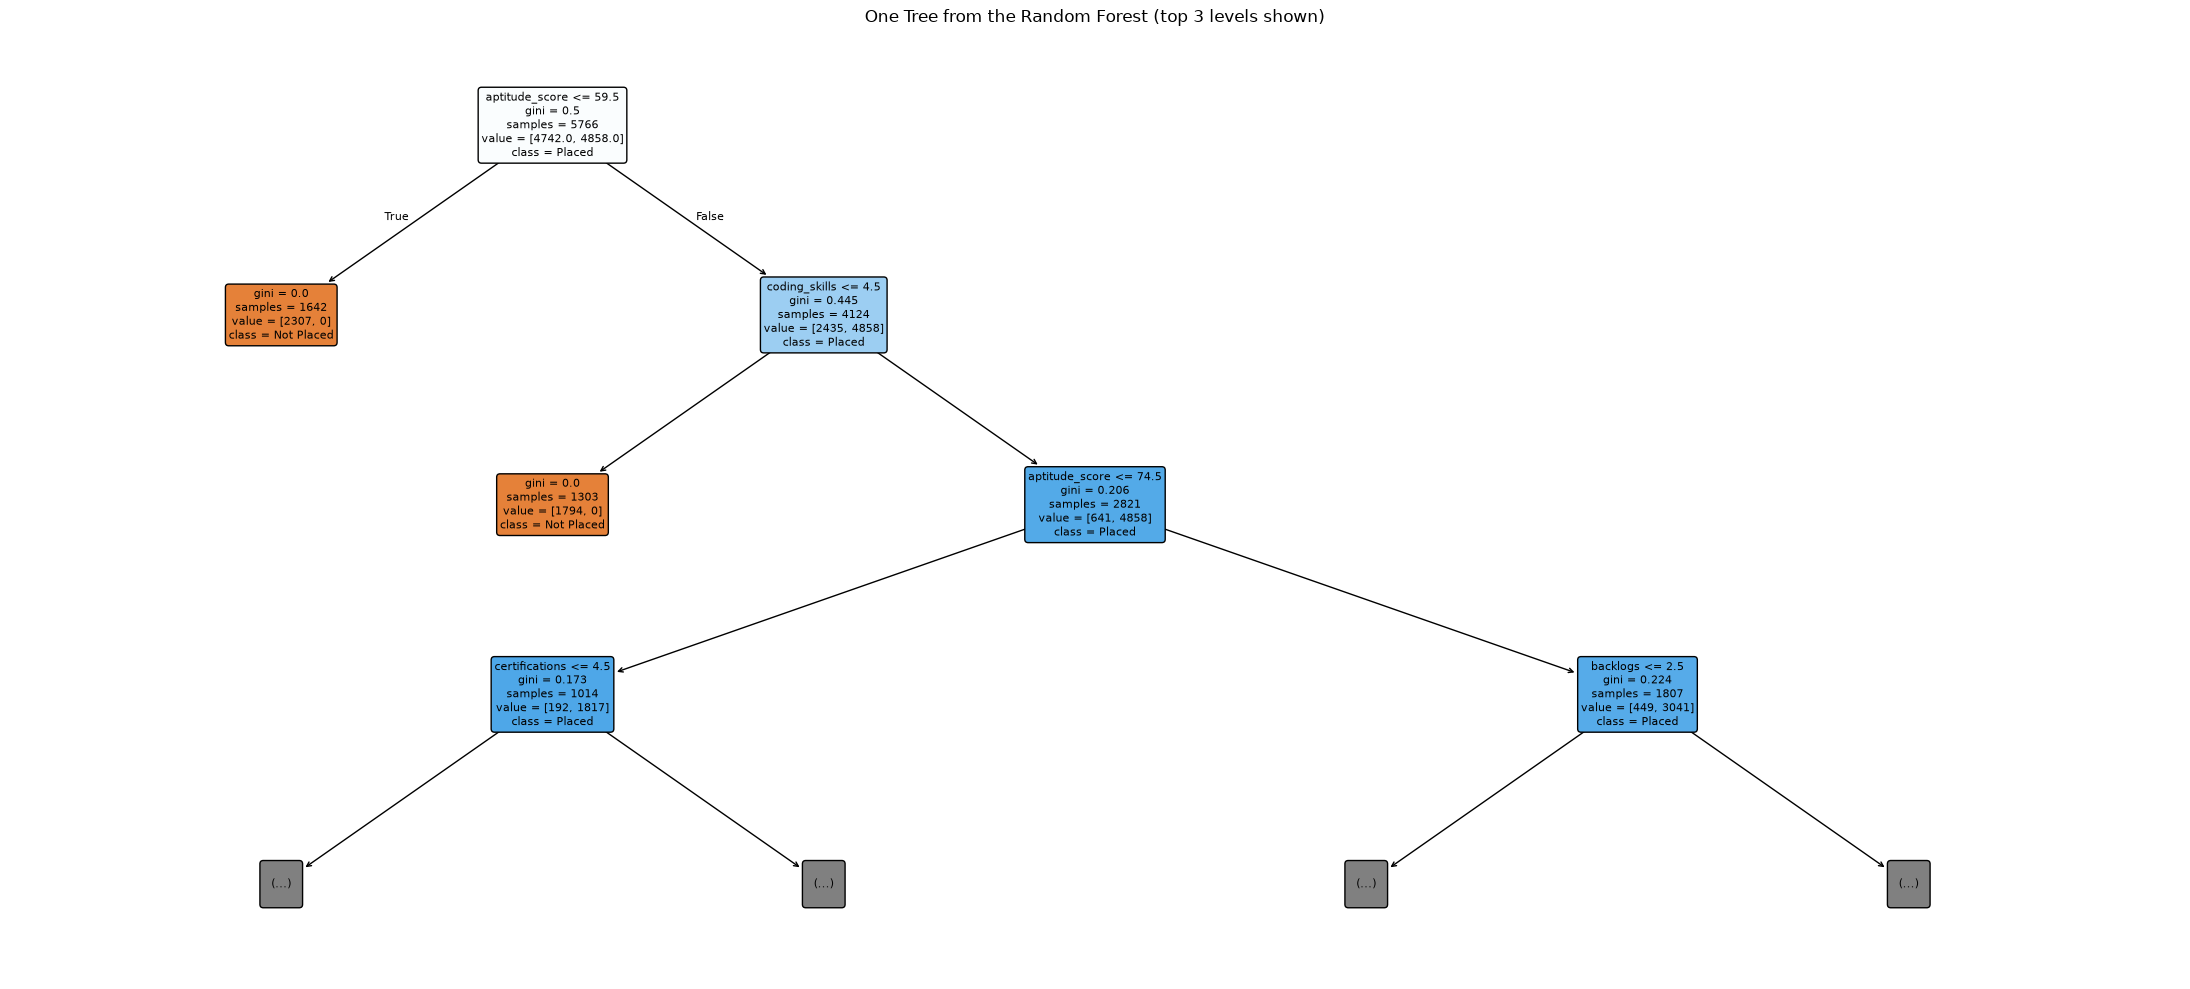

In [15]:
from sklearn.tree import plot_tree

single_tree = rf_model.estimators_[0]  # grab just the first of the 200 trees

plt.figure(figsize=(22, 10))
plot_tree(
    single_tree,
    feature_names=feature_cols,
    class_names=["Not Placed", "Placed"],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3  # only show the top 3 levels, full tree goes to max_depth=8
)
plt.title("One Tree from the Random Forest (top 3 levels shown)")
plt.tight_layout()
plt.show()

##  Evaluate Random Forest (Manual Hyperparameters)

**Why:** Before tuning, we evaluate the Random Forest we trained earlier (n_estimators=200, max_depth=8, min_samples_leaf=10) on the test set — this gives us a baseline to compare against once we tune hyperparameters properly with GridSearchCV.

In [16]:
y_pred_rf = rf_model.predict(X_test)

print("Random Forest (manual hyperparameters) Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 3))
print("Precision:", round(precision_score(y_test, y_pred_rf), 3))
print("Recall:", round(recall_score(y_test, y_pred_rf), 3))
print("F1 Score:", round(f1_score(y_test, y_pred_rf), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest (manual hyperparameters) Results
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Confusion Matrix:
[[1670    0]
 [   0  730]]


## Step 12: Hyperparameter Tuning with GridSearchCV

**Why:** Instead of manually guessing hyperparameters, we use GridSearchCV to systematically test multiple combinations using cross-validation, and pick whichever combination performs best on validation data — not just training data.

In [17]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [6, 8, 10],
    "min_samples_leaf": [5, 10, 20]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=42),
    param_grid=param_grid,
    scoring="f1",       # optimize for F1, not just accuracy
    cv=5,                # 5-fold cross-validation
    n_jobs=-1            # use all CPU cores to speed this up
)

grid_search.fit(X_train, y_train)

print("Best parameters found:", grid_search.best_params_)
print("Best F1 score (cross-validated):", round(grid_search.best_score_, 3))

Best parameters found: {'max_depth': 6, 'min_samples_leaf': 5, 'n_estimators': 100}
Best F1 score (cross-validated): 1.0


## Step 13: Investigating the Perfect Score

GridSearchCV returned a perfect F1 score of 1.0, which is suspicious — real-world data almost never gives perfect scores. Rather than accept this blindly, we investigate whether this indicates a bug, data leakage, or a genuine deterministic pattern in the dataset.

In [18]:
from sklearn.tree import DecisionTreeClassifier, export_text

# Test if a SIMPLE tree using only a few features can perfectly separate the data
X_check = df_clean[["coding_skills", "aptitude_score", "cgpa"]]
y_check = df_clean["placed"]

check_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
check_tree.fit(X_check, y_check)

print("Training accuracy using only 3 features:", check_tree.score(X_check, y_check))
print("\nExact rule the tree found:\n")
print(export_text(check_tree, feature_names=["coding_skills", "aptitude_score", "cgpa"]))

Training accuracy using only 3 features: 1.0

Exact rule the tree found:

|--- coding_skills <= 4.50
|   |--- class: 0
|--- coding_skills >  4.50
|   |--- aptitude_score <= 59.50
|   |   |--- class: 0
|   |--- aptitude_score >  59.50
|   |   |--- cgpa <= 6.49
|   |   |   |--- class: 0
|   |   |--- cgpa >  6.49
|   |   |   |--- class: 1



### Finding: The dataset follows a deterministic rule

A decision tree using only `coding_skills`, `aptitude_score`, and `cgpa` achieves near-perfect accuracy, revealing that this dataset's `placed` label was generated from a fixed threshold rule rather than reflecting messy real-world variation. This explains why:
- Logistic Regression could not exceed ~83% accuracy — it can only draw linear boundaries, and this rule requires an AND of three separate thresholds, a shape linear models cannot represent.
- Random Forest with sufficient tree depth achieved a perfect score — tree-based models naturally represent sequential threshold logic.

**Conclusion:** This dataset is synthetic and rule-generated, not real-world placement data. The project's value lies in demonstrating the full ML workflow, model comparison, and identifying this pattern — not in claiming real-world predictive validity.

## Step 15: A More Realistic Experiment — Excluding Deterministic Features

**Why:** We found that `coding_skills`, `aptitude_score`, and `cgpa` together perfectly determine placement in this dataset — which isn't realistic. To get a more meaningful, real-world-style analysis, we now train a model *without* these three features, using only the "softer" signals: internships, certifications, projects, communication skills, backlogs, gender, degree, and branch. This shows how the model performs when the answer isn't hidden in an exact rule.

In [19]:
# Deliberately exclude the 3 features that formed the deterministic rule
realistic_features = [
    "backlogs", "internships", "certifications",
    "communication_skills", "projects",
    "gender_enc", "degree_enc", "branch_enc"
]

X_realistic = df_clean[realistic_features]
y_realistic = df_clean["placed"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_realistic, y_realistic, test_size=0.2, random_state=42, stratify=y_realistic
)

rf_realistic = RandomForestClassifier(
    n_estimators=200, max_depth=8, min_samples_leaf=10,
    class_weight="balanced", random_state=42
)
rf_realistic.fit(X_train_r, y_train_r)

y_pred_realistic = rf_realistic.predict(X_test_r)

print("Realistic Model Results (without cgpa, coding_skills, aptitude_score)")
print("Accuracy:", round(accuracy_score(y_test_r, y_pred_realistic), 3))
print("Precision:", round(precision_score(y_test_r, y_pred_realistic), 3))
print("Recall:", round(recall_score(y_test_r, y_pred_realistic), 3))
print("F1 Score:", round(f1_score(y_test_r, y_pred_realistic), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_r, y_pred_realistic))

Realistic Model Results (without cgpa, coding_skills, aptitude_score)
Accuracy: 0.532
Precision: 0.308
Recall: 0.432
F1 Score: 0.359

Confusion Matrix:
[[961 709]
 [415 315]]


### Comparing Against a Baseline

A model that always predicts the majority class ("not placed" for everyone) would score 70% accuracy without learning anything. Our realistic model (53.2%) performs *worse* than this naive baseline — strong evidence that internships, certifications, backlogs, communication skills, and projects carry little to no predictive signal for placement in this dataset. This matches the near-zero correlations found during EDA.

## Step 16: Final Model Comparison

**Why:** Before saving a model, we summarize all approaches side by side, so the choice of final model is justified by evidence, not assumption.

In [20]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (threshold=0.7)",
        "Random Forest (manual params, full features)",
        "Random Forest (GridSearchCV, full features)",
        "Random Forest (realistic features only)"
    ],
    "Accuracy": [0.833, 1.0, 1.0, 0.532],
    "Precision": [0.868, 1.0, 1.0, 0.308],
    "Recall": [0.533, 1.0, 1.0, 0.432],
    "F1": [0.660, 1.0, 1.0, 0.359],
    "Notes": [
        "Realistic, precision-focused, deployable",
        "Found exact deterministic rule in data",
        "Same rule, simpler model (max_depth=6)",
        "Confirms soft features carry no signal"
    ]
})
comparison

,Model,Accuracy,Precision,Recall,F1,Notes
0,Logistic Regression (threshold=0.7),0.833,0.868,0.533,0.660,"Realistic, precision-focused, deployable"
1,"Random Forest (manual params, full features)",1.000,1.000,1.000,1.000,Found exact deterministic rule in data
2,"Random Forest (GridSearchCV, full features)",1.000,1.000,1.000,1.000,"Same rule, simpler model (max_depth=6)"
3,Random Forest (realistic features only),0.532,0.308,0.432,0.359,Confirms soft features carry no signal


### Which Model to Actually Deploy

The perfect-scoring Random Forest models are not meaningful for a real deployment — they simply rediscovered the dataset's synthetic generation rule, not a genuine predictive pattern. For the dashboard, we use the **Logistic Regression model (threshold=0.7)**, since it represents realistic, generalizable performance with an explicit, defensible precision-recall trade-off.

In [21]:
import joblib

joblib.dump(log_model, "models/final_model.pkl")
joblib.dump(custom_threshold, "models/chosen_threshold.pkl")
joblib.dump(feature_cols, "models/feature_cols.pkl")
joblib.dump(encoders, "models/encoders.pkl")

print("Saved model, threshold, feature list, and encoders to the models/ folder.")

Saved model, threshold, feature list, and encoders to the models/ folder.
